# The quadrupole that holds a qubit: a Paul trap on the scope bench
### SymPy derivation · voltage vs. time on a simulated oscilloscope · stability map on the GPU (CUDA, Windows)

**In plain words.** Trapped-ion quantum computers hold single atoms with electric fields. Static
voltages can't do it (Earnshaw's theorem: no stable minimum in a charge-free region), so the trap uses
a **quadrupole** whose voltage flips sign tens of millions of times a second. The ion is pushed in
along $x$ and out along $y$, then the roles swap before it can leave; on average it sits in a bowl.

We derive the motion in SymPy, look at the electrode **voltage versus time** and the ion's motion on a
simulated oscilloscope that has a real scope's flaws, map where trapping works with one CUDA thread per
setting, and finish with the number that matters for the qubit: the Lamb-Dicke parameter.

Free software only (numpy, sympy, matplotlib, cupy). Figures use the Okabe-Ito palette, curves differ
by line style too, and each figure has a printed text description.

In [1]:
import sys, pathlib, time, math
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np, sympy as sp, matplotlib.pyplot as plt
from dgs import paul_trap as pt
from dgs.scope_bench import Scope
sp.init_printing()
OI = ["#E69F00", "#56B4E9", "#009E73", "#D55E00", "#CC79A7", "#0072B2"]
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=OI)
print("GPU available:", pt.gpu_available())

GPU available: True


## 1. From the quadrupole to the Mathieu equation (SymPy)

The four rods carry $\pm(U - V\cos\Omega t)/2$, so near the axis
$$\phi(x,y,t) = \big(U - V\cos\Omega t\big)\,\frac{x^2 - y^2}{2r_0^2}.$$
First check it is a legal electrostatic potential (Laplace), then let SymPy turn Newton's law into the
Mathieu equation $u'' + (a - 2q\cos 2\xi)\,u = 0$ with $\xi = \Omega t/2$.

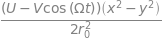

Laplacian of phi: 0
x:  a = 4*U*e/(Omega**2*m*r_0**2)    q = 2*V*e/(Omega**2*m*r_0**2)
y:  a = -4*U*e/(Omega**2*m*r_0**2)    q = -2*V*e/(Omega**2*m*r_0**2)


In [2]:
d = pt.derive_mathieu()
display(d["phi"])
print("Laplacian of phi:", d["laplacian"])
for c in ("x", "y"):
    print(f"{c}:  a =", d[c]["a"], "   q =", d[c]["q"])

The $y$ direction gets $-a$ and $-q$: whatever focuses $x$ defocuses $y$, which is exactly why a
static field fails and the alternating one works.

## 2. When is the ion trapped? (Floquet, exact)

Integrate one RF period to get the monodromy matrix $M$. The motion is bounded when
$|\operatorname{tr} M| < 2$, and then $\operatorname{tr} M = 2\cos\pi\beta$ gives the slow (secular)
frequency $\omega_\text{sec} = \beta\,\Omega/2$. Checks against the textbook: the first stability
region ends at $q = 0.908$ (for $a = 0$), and $\beta \approx q/\sqrt2$ for small $q$.

In [3]:
print(f"edge of stability at a = 0:  q_max = {pt.q_max():.5f}   (textbook 0.90805)")
for q in (0.05, 0.1, 0.3, 0.6):
    print(f"q = {q:4}:  beta = {pt.floquet_beta(0, q):.5f}   lowest-order q/sqrt2 = {q/math.sqrt(2):.5f}")

edge of stability at a = 0:  q_max = 0.90805   (textbook 0.90805)
q = 0.05:  beta = 0.03537   lowest-order q/sqrt2 = 0.03536
q =  0.1:  beta = 0.07085   lowest-order q/sqrt2 = 0.07071
q =  0.3:  beta = 0.21606   lowest-order q/sqrt2 = 0.21213
q =  0.6:  beta = 0.46225   lowest-order q/sqrt2 = 0.42426


## 3. A real qubit trap: 40Ca+

Defaults: $r_0 = 0.5$ mm, $\Omega/2\pi = 20$ MHz, $V = 300$ V, 729 nm qubit laser at 45° to the
trap axis.

In [4]:
p = pt.trap_parameters()
for k, v in p.items():
    print(f"{k:28s} {v:.4g}")
print(f"\ncheck: depth = q V / 8 = {p['q']*300/8:.4g} eV")

q                            0.3666
a                            0
beta                         0.2666
beta_lowest_order            0.2592
secular_MHz                  2.666
rf_MHz                       20
pseudopotential_depth_eV     13.75
ground_state_size_nm         6.884
lamb_dicke_eta               0.04196

check: depth = q V / 8 = 13.75 eV


## 4. Voltage versus time on the scope bench

CH1 is the RF electrode (a 10x probe would be wise at 300 V; here the scope is set to 100 V/div).
CH2 is the ion's position from a camera-style position monitor scaled to 1 V per micrometre (an
honest image-current pickup would be nanovolts). The ion starts 2 µm off axis.

Oscilloscope screen, 10 x 8 divisions, trigger at t = 0 on CH1 (rising through 0 V). CH1 (RF electrode, '-' line): 19.804 MHz, 600 Vpp; CH2 (ion x (1 V/um), '--' line): 7.438 MHz, 5.6 Vpp.
Oscilloscope screen, 10 x 8 divisions, trigger at t = 0 on CH1 (rising through 0 V). CH1 (RF electrode, '-' line): 20.000 MHz, 600 Vpp; CH2 (ion x (1 V/um), '--' line): 2.600 MHz, 5.85 Vpp.


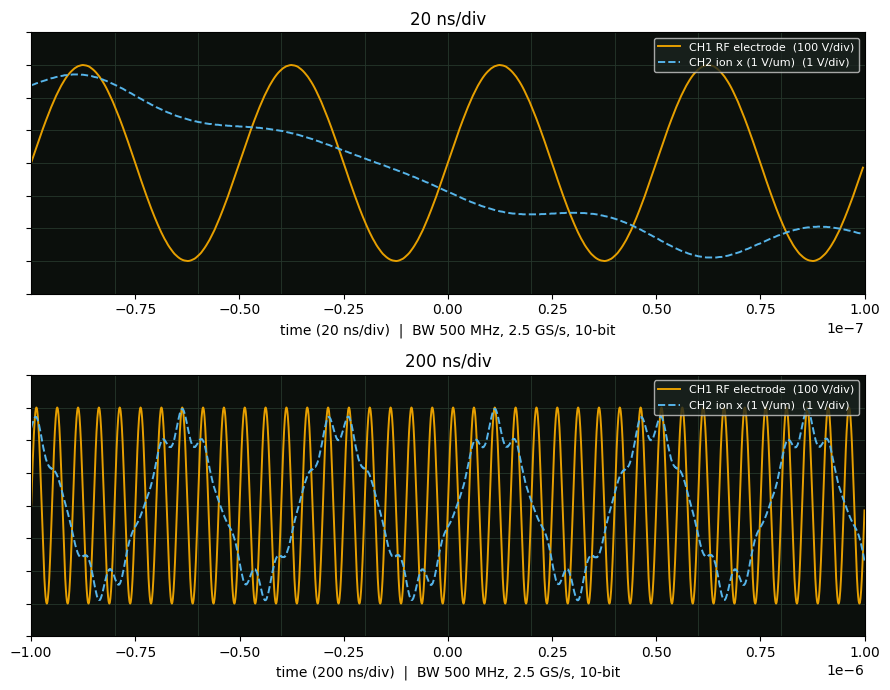


Secular frequency read off the scope: 2.658 MHz;  Floquet: 2.666 MHz


In [5]:
Om = 2*np.pi*20e6
xi, u, _ = pt.ion_trajectory(p["a"], p["q"], n_periods=400, steps_per_period=128, u0=1.0)
t_ion = 2*xi/Om
ion = lambda t: 2.0*np.interp(np.asarray(t) % t_ion[-1], t_ion, u)      # micrometres -> volts (1 V/um)
rf = lambda t: pt.electrode_voltage(t)

scope = Scope(bandwidth=500e6, sample_rate=2.5e9, bits=10)
scope.connect(1, "RF electrode", rf, volts_per_div=100)
scope.connect(2, "ion x (1 V/um)", ion, volts_per_div=1.0)
scope.trigger(1, 0.0, "rising")
fig, ax = plt.subplots(2, 1, figsize=(9, 7))
for a_, tdiv in zip(ax, (20e-9, 200e-9)):
    shot = scope.acquire(time_per_div=tdiv)
    _, desc = scope.plot(shot, ax=a_, title=f"{tdiv*1e9:g} ns/div")
    print(desc)
plt.tight_layout(); plt.show()
m = scope.measure(scope.acquire(time_per_div=2e-6), 2)
print(f"\nSecular frequency read off the scope: {m['frequency']/1e6:.3f} MHz;  Floquet: {p['secular_MHz']:.3f} MHz")

**What the two screens show.** At 20 ns/div the RF voltage (solid orange) swings ±300 V at
20 MHz and the ion trace (dashed blue) carries a small ripple at the same frequency: that is
**micromotion**, the ion being shaken by the RF. At 200 ns/div the ion's large, slow swing is the
**secular** motion in the time-averaged bowl, at $\beta\Omega/2\approx 2.7$ MHz, with the micromotion
riding on it. The scope's own measurement of the secular frequency matches Floquet theory.

## 5. The stability diagram, one CUDA thread per point

Brute force: for every $(a, q)$ integrate both fundamental solutions for 30 RF periods (RK4, float64)
and call it stable if the ion stays bounded. NumPy does it vectorised; the CUDA kernel (a CuPy
`RawKernel`, compiled at run time, so no MSVC or nvcc setup is needed on Windows) runs one thread per
point. Both are checked against the exact Floquet map.

In [6]:
a_vals = np.linspace(-0.35, 0.35, 400); q_vals = np.linspace(0.0, 1.0, 400)
if pt.gpu_available():
    pt.stability_map_gpu(a_vals[:4], q_vals[:4])          # compile + warm up
    t0 = time.perf_counter(); G = pt.stability_map_gpu(a_vals, q_vals); tg = time.perf_counter() - t0
else:
    G, tg = None, float("nan")
t0 = time.perf_counter(); C = pt.stability_map_cpu(a_vals, q_vals); tc = time.perf_counter() - t0
print(f"160,000 trajectories:  CPU (NumPy) {tc:.2f} s,  GPU (CUDA) {tg:.3f} s,  speed-up {tc/tg:.0f}x")
if G is not None:
    print("GPU and CPU maps identical:", bool(np.array_equal(G, C)))
a_s, q_s = np.linspace(-0.3, 0.3, 13), np.linspace(0.02, 1.0, 15)
F = pt.stability_map_floquet(a_s, q_s)
print(f"agreement with exact Floquet on a 13 x 15 check grid: {np.mean(F == pt.stability_map_cpu(a_s, q_s)):.1%}")

160,000 trajectories:  CPU (NumPy) 58.20 s,  GPU (CUDA) 0.496 s,  speed-up 117x
GPU and CPU maps identical: True


agreement with exact Floquet on a 13 x 15 check grid: 99.5%


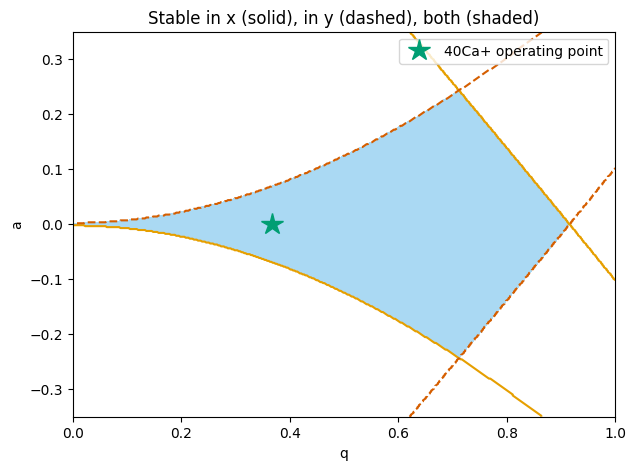

Text description: the shaded wedge is where the ion is stable in both x and y; its tip on the a = 0 axis sits at q = 0.908. The solid orange curve bounds x-stability and the dashed vermillion curve y-stability (the x map mirrored in a). The green star marks the 40Ca+ trap at q = 0.37, a = 0, well inside.


In [7]:
M = G if G is not None else C
both = M & M[::-1]          # x needs (a, q); y needs (-a, -q) -> same map mirrored in a (q sign does not matter)
fig, ax = plt.subplots(figsize=(7, 5))
ax.contourf(q_vals, a_vals, both.astype(float), levels=[0.5, 1.5], colors=[OI[1]], alpha=0.5)
ax.contour(q_vals, a_vals, M.astype(float), levels=[0.5], colors=[OI[0]], linestyles="-")
ax.contour(q_vals, a_vals, M[::-1].astype(float), levels=[0.5], colors=[OI[3]], linestyles="--")
ax.plot(p["q"], p["a"], marker="*", ms=16, color=OI[2], ls="none", label="40Ca+ operating point")
ax.set_xlabel("q"); ax.set_ylabel("a"); ax.legend(); ax.set_title("Stable in x (solid), in y (dashed), both (shaded)")
plt.show()
print("Text description: the shaded wedge is where the ion is stable in both x and y; its tip on the a = 0 "
      "axis sits at q = 0.908. The solid orange curve bounds x-stability and the dashed vermillion curve "
      "y-stability (the x map mirrored in a). The green star marks the 40Ca+ trap at q = "
      f"{p['q']:.2f}, a = 0, well inside.")

## 6. Why the qubit cares: the Lamb-Dicke regime

Gates on trapped ions use lasers that kick the ion's motion. They work cleanly when the ion's
ground-state wave packet is small compared with the light's wavelength, i.e. $\eta^2(2\bar n + 1)\ll 1$.
After Doppler cooling on the 397 nm line ($\Gamma/2\pi = 22$ MHz) the temperature is
$T_D = \hbar\Gamma/2k_B$ and the mean phonon number is $\bar n \approx k_BT/\hbar\omega_\text{sec}$.

In [8]:
kB = 1.380649e-23; hbar = pt.HBAR
Gamma = 2*np.pi*22e6
T_D = hbar*Gamma/(2*kB)
w_sec = 2*np.pi*p["secular_MHz"]*1e6
nbar = kB*T_D/(hbar*w_sec)
eta = p["lamb_dicke_eta"]
print(f"Doppler limit T_D = {T_D*1e3:.3f} mK,  nbar = {nbar:.2f},  eta = {eta:.3f},  eta^2(2nbar+1) = {eta**2*(2*nbar+1):.4f}")
print("Lamb-Dicke regime:", eta**2*(2*nbar+1) < 0.1)

Doppler limit T_D = 0.528 mK,  nbar = 4.13,  eta = 0.042,  eta^2(2nbar+1) = 0.0163
Lamb-Dicke regime: True


## How this connects

* **Notes in this repo.** `dgs.electrostatics_multipoles` has the same $x^2-y^2$ quadrupole field from
  point charges; `dgs.quadrupole_wavefunction` has the same $l = 2$ angular shape in a d orbital;
  `dgs.oscilloscope` has the rules (rise time $0.35/\text{BW}$, Nyquist) that `dgs.scope_bench` turns
  into an instrument; `dgs.qiskit_phase_flip` corrects the dephasing a trapped-ion qubit suffers.
* **The lab desk** (`projects/lab_desk`) uses the same scope ideas (bandwidth, noise) on the optical
  phase-recovery bench.
* **CUDA on Windows.** `dgs.paul_trap.stability_map_gpu` is a CuPy `RawKernel`: CUDA C compiled at run
  time by NVRTC, so it needs only the NVIDIA driver and CuPy, not the MSVC + nvcc chain described in
  CLAUDE.md for the `.cu` builds. Tested on an RTX 4060.
* **Tests:** `PYTHONPATH=. python -m pytest tests/test_paul_trap.py -q`.